# Data preparation

This notebook turns the raw Sensor Logger exports into labeled windows of 255 readings (5.1 seconds).
For each activity it loads the accelerometer and gyroscope files, merges them into one
table, trims the settling period at the start, and cuts the rest into fixed-length windows.


In [1]:
from pathlib import Path

import pandas as pd

RAW_DIR = Path("../data/raw")
ACTIVITIES = ["Standing", "Walking", "Jumping", "Still"]

SAMPLING_RATE_HZ = 50
WINDOW_SECONDS = 5.1  # the span from first to last timestamp is then at least 5 s
WINDOW_ROWS = round(SAMPLING_RATE_HZ * WINDOW_SECONDS)  # 255 readings per window
TRIM_SECONDS = 5  # settling motion at the start of each recording

AXES = ["x", "y", "z"]
COLUMNS = ["time_s"] + [f"acc_{a}" for a in AXES] + [f"gyro_{a}" for a in AXES]

## Load and merge the two sensors

The accelerometer and gyroscope files use the same column names, so the columns are
renamed with a sensor prefix. Columns are always selected by name, because the raw files
list them in the order z, y, x. The two files must have the same rows at the same times,
which is checked before they are merged.

In [2]:
def load_recording(activity, raw_dir=RAW_DIR):
    """Return one table with time_s and the six sensor columns for an activity."""
    acc = pd.read_csv(raw_dir / activity / "Accelerometer.csv")
    gyro = pd.read_csv(raw_dir / activity / "Gyroscope.csv")

    if len(acc) != len(gyro) or not (acc["time"].values == gyro["time"].values).all():
        raise ValueError(f"{activity}: accelerometer and gyroscope timestamps do not match")

    table = pd.DataFrame({"time_s": acc["seconds_elapsed"]})
    for axis in AXES:
        table[f"acc_{axis}"] = acc[axis]
    for axis in AXES:
        table[f"gyro_{axis}"] = gyro[axis]
    return table[COLUMNS]


recordings = {activity: load_recording(activity) for activity in ACTIVITIES}
for activity, table in recordings.items():
    print(f"{activity:9s} rows={len(table)}  duration={table['time_s'].iloc[-1]:.1f}s")

Standing  rows=6136  duration=123.0s
Walking   rows=6190  duration=124.1s
Jumping   rows=6135  duration=123.0s
Still     rows=6167  duration=123.7s


## Trim and cut into windows

The first 5 seconds are removed because the phone is still being placed or the movement
has not started yet. The rest is cut into consecutive windows of 255 rows (5.1 seconds at
50 Hz, so each file spans more than 5 s from its first to its last timestamp). A final stretch shorter than a full window is dropped, so every window has the same
length and gives comparable features.

In [3]:
def trim_start(table, seconds=TRIM_SECONDS):
    """Drop the readings recorded in the first `seconds` of the recording."""
    return table[table["time_s"] >= seconds].reset_index(drop=True)


def split_into_windows(table, window_rows=WINDOW_ROWS):
    """Cut a table into consecutive, non-overlapping windows of equal length."""
    n_windows = len(table) // window_rows
    return [
        table.iloc[i * window_rows:(i + 1) * window_rows].reset_index(drop=True)
        for i in range(n_windows)
    ]


windows = {
    activity: split_into_windows(trim_start(table))
    for activity, table in recordings.items()
}

summary = pd.DataFrame({
    "windows": {a: len(w) for a, w in windows.items()},
    "seconds_used": {a: len(w) * WINDOW_SECONDS for a, w in windows.items()},
})
summary.loc["total"] = summary.sum()
summary

,windows,seconds_used
Standing,23.0,117.3
Walking,23.0,117.3
Jumping,23.0,117.3
Still,23.0,117.3
total,92.0,469.2


## Checks

Every window must have exactly 255 rows, exactly 6 sensor columns plus time, and no empty values.
Consecutive windows of one activity must follow each other without a gap or overlap.

In [4]:
for activity, activity_windows in windows.items():
    for number, window in enumerate(activity_windows, start=1):
        assert len(window) == WINDOW_ROWS, (activity, number, len(window))
        assert list(window.columns) == COLUMNS
        assert not window.isna().any().any()
    for before, after in zip(activity_windows, activity_windows[1:]):
        step = after["time_s"].iloc[0] - before["time_s"].iloc[-1]
        assert abs(step - 1 / SAMPLING_RATE_HZ) < 1e-4, (activity, step)

print("All windows pass the checks.")

All windows pass the checks.


## Save the windows

Each window is saved as its own CSV file, in a folder named after the activity, for example
`data/processed/walking/walking_07.csv`. The files are numbered in time order, and `time_s`
inside each file gives the position in the original recording. An `activity` column holds
the label.

In [5]:
PROCESSED_DIR = Path("../data/processed")


def save_windows(activity, activity_windows, out_dir=PROCESSED_DIR):
    """Write each window to <out_dir>/<activity>/<activity>_NN.csv with an activity label."""
    folder = out_dir / activity.lower()
    folder.mkdir(parents=True, exist_ok=True)
    for number, window in enumerate(activity_windows, start=1):
        labeled = window.assign(activity=activity)
        labeled.to_csv(folder / f"{activity.lower()}_{number:02d}.csv", index=False)


for activity, activity_windows in windows.items():
    save_windows(activity, activity_windows)

print(sum(len(w) for w in windows.values()), "files written to", PROCESSED_DIR)

92 files written to ..\data\processed


## Sample windows

One 5.1-second window per activity, taken from the middle of each recording. The top row
shows the accelerometer and the bottom row the gyroscope. Each row shares one vertical
scale across the four activities, so differences in how strongly the signal moves can be
compared directly.

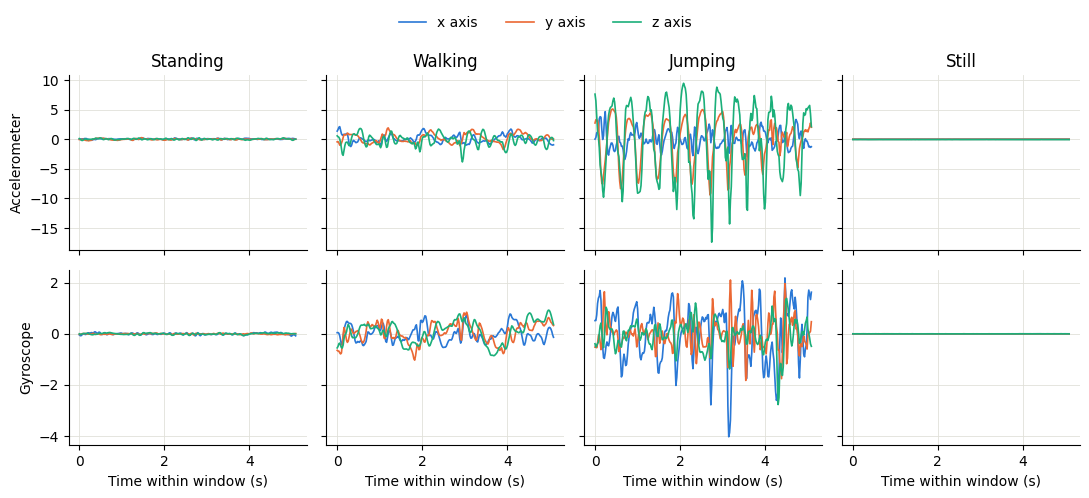

In [6]:
import matplotlib.pyplot as plt

AXIS_COLORS = {"x": "#2a78d6", "y": "#eb6834", "z": "#1baf7a"}
SAMPLE_WINDOW = 12  # a window from the middle of each recording (1-based)
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, len(ACTIVITIES), figsize=(11, 5), sharex=True, sharey="row")
for col, activity in enumerate(ACTIVITIES):
    window = windows[activity][SAMPLE_WINDOW - 1]
    t = window["time_s"] - window["time_s"].iloc[0]
    for row, sensor in enumerate(["acc", "gyro"]):
        ax = axes[row, col]
        for axis in AXES:
            ax.plot(t, window[f"{sensor}_{axis}"], color=AXIS_COLORS[axis], linewidth=1.2, label=f"{axis} axis")
        ax.grid(color="#e1e0d9", linewidth=0.6)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[0, col].set_title(activity)
    axes[1, col].set_xlabel("Time within window (s)")

axes[0, 0].set_ylabel("Accelerometer")
axes[1, 0].set_ylabel("Gyroscope")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGURES_DIR / "sample_windows.png", dpi=200, bbox_inches="tight")
plt.show()